## 1. Setup
Libraries to set up for our analysis (we downloaded more than necessary to make sure we were going to be covered in any analysis that we wanted to do!)

In [ ]:
import sys
import zipfile
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from scipy.stats import rankdata, chi2
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (unlocks IterativeImputer)
from sklearn.impute import IterativeImputer
from sklearn.covariance import MinCovDet
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.0f}" if float(x).is_integer() and abs(x) >= 1 else f"{x:,.3f}")

# ---- analysis settings (change here, everything downstream follows) ----
SEED = 42                 # fixes every random step so results reproduce exactly
UNICORN_SHARE = 0.05      # top 5% of Mahalanobis scores within each position = unicorns
ATHLETIC_CUT = 0.75       # athleticism composite (SD) that separates Freak / Odd build / Red flag
MCD_SUPPORT = 0.85        # share of players the robust covariance is fitted on
MIN_DRILL_COVERAGE = 0.25 # a drill is skipped for a position if <25% of prospects did it (e.g. QB bench)
MATURE_LAST = 2015        # draft classes used to fit the slot-value curve (careers essentially complete)
LAST_GRADED = 2022        # last draft class graded (needs ≥ 4 seasons)
N_BOOT = 4000             # bootstrap resamples for confidence intervals
RNG = np.random.default_rng(SEED)

# ---- chart style ----
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10.5, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "axes.axisbelow": True, "legend.frameon": False})
TYPE_ORDER = ["Freak", "Odd build", "Red flag", "Typical"]
TYPE_COLOR = {"Freak": "#E69F00", "Odd build": "#7B5EA7", "Red flag": "#D1495B", "Typical": "#9AA3AD"}
GRADE_COLOR = {"Bust": "#D1495B", "Good value": "#8FA3B8", "Steal": "#2A9D8F"}
POSITIONS = ["QB", "RB", "WR", "TE", "OT", "IOL", "DT", "EDGE", "LB", "CB", "S"]

### Load the source data
**Sources.** All three files come from the open **nflverse** project, which redistributes
Pro-Football-Reference tables (github.com/nflverse/nflverse-data, releases `combine`, `draft_picks`, `players`):

| File | Contents |
|---|---|
| `combine.csv` | Every combine prospect 2000–2026: height, weight, 40-yard dash, bench, vertical, broad jump, 3-cone, shuttle, and draft slot |
| `draft_picks.csv` | Every draft pick since 1980 with career weighted Approximate Value (AV), games, starts, Pro Bowls |
| `players.csv` | NFL roster positions, used to resolve generic combine labels (OL, DL, DB) |

nflverse updates these files during the season, so we use the **October 2026 snapshot** stored in the
replication zip. The checksums below confirm the files are exactly the ones the paper used.

In [ ]:
SNAPSHOT_SHA256 = {
    "combine.csv": "5648886b1bb9de8a0c42b05ee7b1d9cbe58897676caaa2f6a4a3d3c9228235bb",
    "draft_picks.csv": "769633acc15f9539cf3e57a8ed2bf95c6392b038e765cef60a4542d6da3a03f8",
    "players.csv": "7ea1f10f0c3b0bf5c026a4b5935c6d01e4a72864a3122594a6df493b5bf29d97",
}

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Pricing the Unicorn")
    DATA = Path("/content/data")
    DATA.mkdir(exist_ok=True)
    with zipfile.ZipFile(PROJECT / "unicorn_replication_package.zip") as archive:
        for name in SNAPSHOT_SHA256:
            (DATA / name).write_bytes(archive.read(f"data/{name}"))
    OUT = PROJECT / "milestone2_outputs"
else:  # running locally: expects a data/ folder next to the notebook
    DATA = Path("data")
    OUT = Path("milestone2_outputs")
OUT.mkdir(exist_ok=True)

for name, expected in SNAPSHOT_SHA256.items():
    actual = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    assert actual == expected, f"{name} is not the October 2026 snapshot"
print("All three source files verified.")

combine = pd.read_csv(DATA / "combine.csv")
draft = pd.read_csv(DATA / "draft_picks.csv")
players = pd.read_csv(DATA / "players.csv", low_memory=False)
display(pd.DataFrame({"rows": [len(combine), len(draft), len(players)],
                      "columns": [combine.shape[1], draft.shape[1], players.shape[1]]},
                     index=["combine", "draft_picks", "players"]))
display(combine[["season", "player_name", "pos", "school", "ht", "wt", "forty", "vertical", "draft_ovr"]].head())

Mounted at /content/drive
All three source files verified.


,rows,columns
combine,8968,18
draft_picks,12927,36
players,24844,39


,season,player_name,pos,school,ht,wt,forty,vertical,draft_ovr
0,2000,John Abraham,OLB,South Carolina,6-4,252,4.550,NaN,13
1,2000,Shaun Alexander,RB,Alabama,6-0,218,4.580,NaN,19
2,2000,Darnell Alford,OT,Boston Col.,6-4,334,5.560,25,188
3,2000,Kyle Allamon,TE,Texas Tech,6-2,253,4.970,29,NaN
4,2000,Rashard Anderson,CB,Jackson State,6-2,206,4.550,34,23


## 2. Build the modelling sample
Steps, each logged below:
1. Convert height from `"6-4"` to inches.
2. The combine file has no draft slots for 2026 yet, so 2026 prospects are matched to the draft file by exact name.
3. Attach each drafted player's career AV by (draft year, overall pick), and his NFL roster position.
4. **Namesakes**: the source occasionally gives one draft pick to two same-named prospects. We keep the one whose
   position family matches the drafted position.
5. Assign 11 position groups (generic labels such as `OL` are resolved with the roster position, then by size).

In [ ]:
def height_to_inches(value):
    """'6-4' -> 76.0; anything unreadable -> NaN."""
    try:
        feet, inches = str(value).split("-")
        return 12 * int(feet) + int(inches)
    except ValueError:
        return np.nan


def position_group(row):
    """Map a combine position to one of 11 groups, using NFL roster position for generic labels."""
    pos, ht, wt = row["pos"], row["ht"], row["wt"]
    roster = row["nfl_pos"] if isinstance(row["nfl_pos"], str) else row["draft_pos"]
    direct = {"QB": "QB", "RB": "RB", "WR": "WR", "TE": "TE", "OT": "OT", "OG": "IOL", "G": "IOL", "C": "IOL",
              "DT": "DT", "DE": "EDGE", "EDGE": "EDGE", "ILB": "LB", "LB": "LB", "CB": "CB", "S": "S", "SAF": "S"}
    if pos in direct:
        return direct[pos]
    if pos == "OL":
        if roster in ("T", "OT"): return "OT"
        if roster in ("G", "C"): return "IOL"
        return "OT" if ht >= 77 else "IOL"
    if pos == "DL":
        if roster in ("DT", "NT"): return "DT"
        if roster in ("DE", "OLB", "LB"): return "EDGE"
        return "DT" if wt >= 285 else "EDGE"
    if pos == "OLB":
        return "EDGE" if wt >= 245 else "LB"
    if pos == "DB":
        if roster == "CB": return "CB"
        if roster in ("S", "SAF", "FS", "SS"): return "S"
        return "S" if wt >= 200 else "CB"
    return None  # kickers, punters, long snappers, fullbacks


POSITION_FAMILY = {**dict.fromkeys(["QB", "RB", "FB", "WR", "TE"], "O"),
                   **dict.fromkeys(["T", "OT", "G", "OG", "C", "OL"], "OL"),
                   **dict.fromkeys(["DT", "NT", "DE", "DL", "EDGE", "LB", "OLB", "ILB"], "F7"),
                   **dict.fromkeys(["CB", "DB", "S", "SAF", "FS", "SS"], "DB")}
RELOCATED = {"STL": "LAR", "SDG": "LAC", "OAK": "LVR"}

In [ ]:
log = []
df = combine.copy()
df["ht"] = df["ht"].map(height_to_inches)
log.append(("Combine records, 2000–2026", len(df)))

# 2026 draft slots by exact name
picks_2026 = draft[draft.season.eq(2026)].drop_duplicates("pfr_player_name").set_index("pfr_player_name")
is_2026 = df.season.eq(2026) & df.player_name.isin(picks_2026.index)
df.loc[is_2026, "draft_year"] = 2026
df.loc[is_2026, "draft_round"] = df.loc[is_2026, "player_name"].map(picks_2026["round"])
df.loc[is_2026, "draft_ovr"] = df.loc[is_2026, "player_name"].map(picks_2026["pick"])
print(f"2026 prospects matched to a pick by name: {is_2026.sum()}")

# career outcomes and roster positions
outcomes = (draft[draft.season.ge(2000)][["season", "pick", "team", "position", "w_av"]]
            .rename(columns={"season": "draft_year", "pick": "draft_ovr", "position": "draft_pos"}))
df = df.merge(outcomes, on=["draft_year", "draft_ovr"], how="left", validate="many_to_one")
roster = players[["pfr_id", "position"]].dropna().drop_duplicates("pfr_id").rename(columns={"position": "nfl_pos"})
df = df.merge(roster, on="pfr_id", how="left", validate="many_to_one")

# namesakes: one pick, two prospects -> keep the position match
shared_pick = df.draft_ovr.notna() & df.duplicated(["draft_year", "draft_ovr"], keep=False)
df["_match"] = df.pos.map(POSITION_FAMILY).eq(df.draft_pos.map(POSITION_FAMILY)).astype(int)
keep = (df[shared_pick].sort_values("_match", ascending=False, kind="stable")
        .drop_duplicates(["draft_year", "draft_ovr"]).index)
df = df[~shared_pick | df.index.isin(keep)].drop(columns="_match")
log.append(("Drop namesakes sharing one draft pick", len(df)))

df["grp"] = df.apply(position_group, axis=1)
df = df[df.grp.notna()]
log.append(("Keep the 11 position groups", len(df)))

df = df.dropna(subset=["ht", "wt", "forty"])
log.append(("Require height, weight and 40 time", len(df)))

impossible = (df.grp.isin(["OT", "IOL"]) & df.wt.lt(270)) | (df.grp.eq("LB") & ~df.wt.between(210, 275))
data_errors = df[impossible][["player_name", "season", "pos", "grp", "ht", "wt", "forty"]]
df = df[~impossible].copy().reset_index(drop=True)
df["pid"] = np.arange(len(df))  # stable prospect id
log.append(("Remove sizes impossible for the position", len(df)))

df["drafted"] = df.draft_ovr.notna()
df["franchise"] = df.team.replace(RELOCATED)
DRILLS = ["forty", "bench", "vertical", "broad_jump", "cone", "shuttle"]
df["n_drills"] = df[DRILLS].notna().sum(axis=1)

sample_log = pd.DataFrame(log, columns=["Step", "Rows remaining"])
sample_log["Removed"] = (-sample_log["Rows remaining"].diff()).fillna(0).astype(int)
display(sample_log)
display(Markdown("**Rows removed as data errors:**"))
display(data_errors)

2026 prospects matched to a pick by name: 211


,Step,Rows remaining,Removed
0,"Combine records, 2000–2026",8968,0
1,Drop namesakes sharing one draft pick,8958,10
2,Keep the 11 position groups,8528,430
3,"Require height, weight and 40 time",7699,829
4,Remove sizes impossible for the position,7690,9


**Rows removed as data errors:**

,player_name,season,pos,grp,ht,wt,forty
841,Ben Miller,2002,C,IOL,74,263,4.920
1311,Josh Buhl,2004,OLB,LB,71,204,4.730
6615,Nick Coe,2020,LB,LB,77,280,4.890
6973,Tyler Coyle,2021,LB,LB,73,209,4.380
7048,Noah Hannon,2021,OL,IOL,72,238,5.150
7205,Jarrett Patterson,2021,OL,IOL,66,195,4.520
7263,DAnte Smith,2021,LB,LB,77,305,5.290
7331,Jarell White,2021,LB,LB,68,202,4.580
7339,Carson Williams,2021,OL,IOL,76,254,4.790


### What the sample looks like

,prospects,drafted,mean_ht,mean_wt,mean_forty,mean_drills
grp,,,,,,
QB,413,239,74.690,222.180,4.810,4.350
RB,716,424,70.420,213.120,4.550,4.470
WR,1156,708,72.740,201.010,4.510,4.360
TE,452,299,76.290,252.950,4.760,4.740
OT,608,440,77.640,315.400,5.230,4.760
IOL,722,433,75.820,311.020,5.260,4.860
DT,604,431,74.960,306.740,5.090,4.590
EDGE,826,604,75.520,263.240,4.780,4.660
LB,718,483,73.410,237.120,4.690,4.630


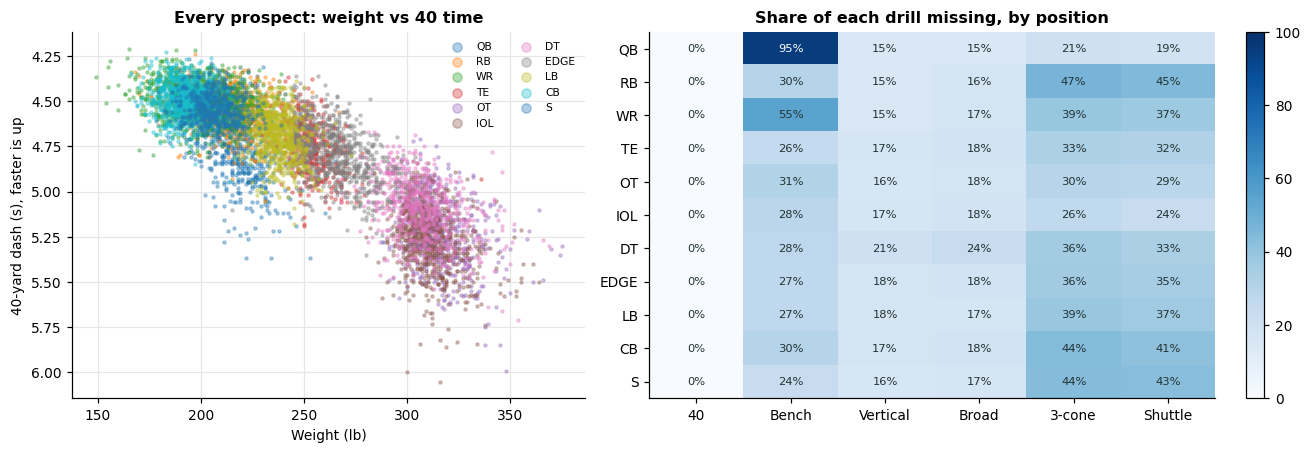

Modelling sample: 7,690 prospects, 5,081 drafted; 23.7% of drill results missing


In [ ]:
census = df.groupby("grp").agg(prospects=("player_name", "size"), drafted=("drafted", "sum"),
                               mean_ht=("ht", "mean"), mean_wt=("wt", "mean"), mean_forty=("forty", "mean"),
                               mean_drills=("n_drills", "mean")).reindex(POSITIONS)
display(census.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
for g in POSITIONS:
    s = df[df.grp == g]
    axes[0].scatter(s.wt, s.forty, s=4, alpha=.35, label=g)
axes[0].invert_yaxis()
axes[0].set(title="Every prospect: weight vs 40 time", xlabel="Weight (lb)", ylabel="40-yard dash (s), faster is up")
axes[0].legend(ncol=2, fontsize=7, markerscale=3)
missing = df.groupby("grp")[DRILLS].agg(lambda x: x.isna().mean() * 100).reindex(POSITIONS)
im = axes[1].imshow(missing, cmap="Blues", vmin=0, vmax=100, aspect="auto")
axes[1].set_xticks(range(6), ["40", "Bench", "Vertical", "Broad", "3-cone", "Shuttle"])
axes[1].set_yticks(range(11), POSITIONS)
axes[1].grid(False)
for i in range(11):
    for j in range(6):
        v = missing.iloc[i, j]
        axes[1].text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=7.5, color="white" if v > 55 else "#233")
axes[1].set_title("Share of each drill missing, by position")
plt.colorbar(im, ax=axes[1], fraction=.03)
plt.tight_layout()
plt.show()
print(f"Modelling sample: {len(df):,} prospects, {df.drafted.sum():,} drafted; "
      f"{df[DRILLS].isna().values.mean():.1%} of drill results missing")

## 3. Features: size- and era-adjusted drill scores
A 4.9-second 40 is slow for a receiver and remarkable for a nose tackle, and even within a position heavier players
run slower. So for each position and drill we fit a regression on players who actually ran it:

$$\text{drill} = \beta_0 + \beta_1\,\text{height} + \beta_2\,\text{weight} + \beta_3\,\text{weight}^2 + \beta_4\,\text{year} + \beta_5\,\mathbf{1}[\text{2021}] + \varepsilon$$

The residual says how much better or worse a player tested than his size and era predict. It is then scaled
**robustly** (median and MAD instead of mean and SD, so the outliers we are hunting don't distort the yardstick)
and flipped so that **positive always means better**. 2021 gets its own term because there was no combine that
year; its numbers are hand-timed pro-day results.

**Missing drills** are filled by iterative imputation within position (each drill predicted from the others).
Imputed values sit near the middle of the distribution, so imputation can only make a player look *less* unusual.

The **athleticism composite** (`ath_z`) is the average of a player's adjusted drill scores, standardized within position.

In [ ]:
HIGHER_IS_BETTER = {"forty": False, "bench": True, "vertical": True, "broad_jump": True, "cone": False, "shuttle": False}


def robust_z(values, reference=None):
    """(x - median) / (1.4826 * MAD); the location and scale come from `reference` if given."""
    ref = values if reference is None else reference
    median = np.median(ref)
    mad = 1.4826 * np.median(np.abs(ref - median))
    return (values - median) / mad


def adjust_position(group):
    """Impute missing drills and return size/era-adjusted, oriented drill scores for one position group."""
    drills = [d for d in DRILLS if group[d].notna().mean() >= MIN_DRILL_COVERAGE]
    raw = group[["ht", "wt"] + drills]
    filled = pd.DataFrame(IterativeImputer(random_state=SEED, max_iter=25).fit_transform(raw),
                          columns=raw.columns, index=group.index)
    design = np.column_stack([np.ones(len(group)), filled.ht, filled.wt, filled.wt ** 2,
                              group.season - 2013, group.season.eq(2021).astype(float)])
    out = pd.DataFrame(index=group.index)
    out["z_ht"] = robust_z(filled.ht.values)
    out["z_wt"] = robust_z(filled.wt.values)
    for d in DRILLS:
        if d not in drills:
            out["adj_" + d] = np.nan
            continue
        measured = group[d].notna().values
        beta, *_ = np.linalg.lstsq(design[measured], filled[d].values[measured], rcond=None)
        residual = filled[d].values - design @ beta
        sign = 1 if HIGHER_IS_BETTER[d] else -1
        out["adj_" + d] = sign * robust_z(residual, residual[measured])
    athleticism = out[["adj_" + d for d in drills]].mean(axis=1)
    out["ath_z"] = (athleticism - athleticism.mean()) / athleticism.std()
    out["features"] = ",".join(["z_ht", "z_wt"] + ["adj_" + d for d in drills])
    return out


features = pd.concat([adjust_position(group) for _, group in df.groupby("grp")])
df = df.join(features)
ADJ = ["adj_" + d for d in DRILLS]
display(df[["player_name", "season", "grp", "ht", "wt", "forty", "z_ht", "z_wt", "adj_forty", "adj_vertical", "ath_z"]]
        .sort_values("adj_forty", ascending=False).head(8).round(2))

,player_name,season,grp,ht,wt,forty,z_ht,z_wt,adj_forty,adj_vertical,ath_z
3091,Bruce Campbell,2010,OT,78,314,4.750,0.000,0.100,3.200,1.220,1.790
1874,Vernon Davis,2006,TE,75,254,4.380,-0.670,0.220,3.160,2.870,3.450
3986,Terron Armstead,2013,OT,77,306,4.710,-0.670,-0.670,3.030,1.900,1.980
6673,Jordan Davis,2022,DT,78,341,4.780,2.020,2.620,2.960,1.730,3.080
851,Donte' Stallworth,2002,WR,72,197,4.220,-0.340,-0.250,2.940,0.970,1.860
1543,Elton Brown,2005,IOL,77,329,4.930,0.670,1.930,2.940,0.870,2.190
4105,Lane Johnson,2013,OT,78,303,4.720,0.000,-0.960,2.890,1.590,2.370
6501,Jayson Oweh,2021,EDGE,77,257,4.360,1.350,-0.340,2.880,1.970,2.700


## 4. Primary method: robust Mahalanobis distance
**Idea.** For each prospect we ask: *how far is this profile from the centre of his position group, measured in
units that respect how the measurements normally move together?* That is the Mahalanobis distance:

$$D^2(\mathbf{x}) = (\mathbf{x}-\boldsymbol\mu)^\top \boldsymbol\Sigma^{-1} (\mathbf{x}-\boldsymbol\mu)$$

Plain Euclidean distance would treat "fast" and "explosive" as independent surprises. They aren't: fast players
usually jump well. Dividing by the covariance $\boldsymbol\Sigma$ means that a player who is fast **but not**
explosive, or heavy **and** fast, gets a large distance. Unusual *combinations* are what make a unicorn.

**Why robust.** If $\boldsymbol\mu$ and $\boldsymbol\Sigma$ were ordinary means and covariances, the unicorns
themselves would stretch them and hide. The **Minimum Covariance Determinant** (MCD) estimator fits the centre and
shape on the tightest 85% of players only, so the outliers are measured against a clean "normal" range.

**Two views per position.**
- *Full workout*: height, weight and every adjusted drill (some imputed).
- *Size–speed*: height, weight and adjusted 40 only, all measured for everyone. This catches players such as
  Calvin Johnson, whose only recorded drill is the 40.

Each view's $D^2$ is turned into a percentile within the position. A player's **unicorn score** is the higher of
his two percentiles, re-ranked; the top 5% are **unicorns**. Under normality $D^2$ follows a $\chi^2$ distribution
with as many degrees of freedom as features, which gives a second, model-based cutoff we use as a robustness check.

In [ ]:
def robust_mahalanobis(X):
    """Squared robust Mahalanobis distance of every row of X, plus the fitted MCD model."""
    mcd = MinCovDet(support_fraction=MCD_SUPPORT, random_state=SEED).fit(X)
    return mcd.mahalanobis(X), mcd


def percentile_rank(values):
    return rankdata(values) / len(values)


def biggest_driver(X, mcd, names):
    """Which feature contributes most to each player's distance: (x-μ)_j · [Σ⁻¹(x-μ)]_j."""
    centred = X - mcd.location_
    contribution = centred * (centred @ mcd.get_precision())
    return np.array(names)[contribution.argmax(axis=1)]


scores = []
for g, group in df.groupby("grp"):
    full_cols = group.features.iloc[0].split(",")
    views = {"full": full_cols, "core": ["z_ht", "z_wt", "adj_forty"]}
    s = pd.DataFrame(index=group.index)
    for view, cols in views.items():
        X = group[cols].values
        d2, mcd = robust_mahalanobis(X)
        s[f"d2_{view}"] = d2
        s[f"pct_{view}"] = percentile_rank(d2)
        s[f"chi2_p_{view}"] = chi2.sf(d2, df=len(cols))  # tail probability if profiles were multivariate normal
        if view == "full":
            s["driver"] = biggest_driver(X, mcd, cols)
    s["md_score"] = s[["pct_full", "pct_core"]].max(axis=1)
    s["md_pct"] = percentile_rank(s.md_score)
    scores.append(s)

df = df.join(pd.concat(scores))
df["unicorn"] = df.md_pct > 1 - UNICORN_SHARE


def unicorn_type(row):
    if not row.unicorn:
        return "Typical"
    if row.ath_z >= ATHLETIC_CUT:
        return "Freak"       # rare AND more athletic than his size predicts
    if row.ath_z <= -ATHLETIC_CUT:
        return "Red flag"    # rare because he tested far below his size peers
    return "Odd build"       # rare mainly through body dimensions or a mixed profile


df["utype"] = df.apply(unicorn_type, axis=1)
DRIVER_LABEL = {"z_ht": "Height", "z_wt": "Weight", "adj_forty": "40 speed", "adj_bench": "Bench",
                "adj_vertical": "Vertical", "adj_broad_jump": "Broad jump", "adj_cone": "3-cone", "adj_shuttle": "Shuttle"}
df["driver"] = df.driver.map(DRIVER_LABEL)

counts = pd.crosstab(df.grp, df.utype).reindex(index=POSITIONS, columns=TYPE_ORDER)
counts.loc["All"] = counts.sum()
display(counts)
print(f"{df.unicorn.sum()} unicorns: " + ", ".join(f"{(df.utype == t).sum()} {t}" for t in TYPE_ORDER[:3]))

utype,Freak,Odd build,Red flag,Typical
grp,,,,
QB,7,7,7,392
RB,5,14,18,679
WR,19,21,18,1098
TE,4,11,8,429
OT,6,13,12,577
IOL,9,14,13,686
DT,10,14,6,574
EDGE,14,12,15,785
LB,7,15,14,682


388 unicorns: 99 Freak, 151 Odd build, 138 Red flag


### Does the χ² assumption hold?
If profiles were multivariate normal, the robust $D^2$ would line up with the χ² line in a Q–Q plot. The tails bend
upward: real athletes produce more extreme profiles than a normal model expects. That is why we flag by **percentile
rank within position** (a fixed 5% per group) rather than a χ² p-value, and keep the χ² cutoff as a sensitivity check.

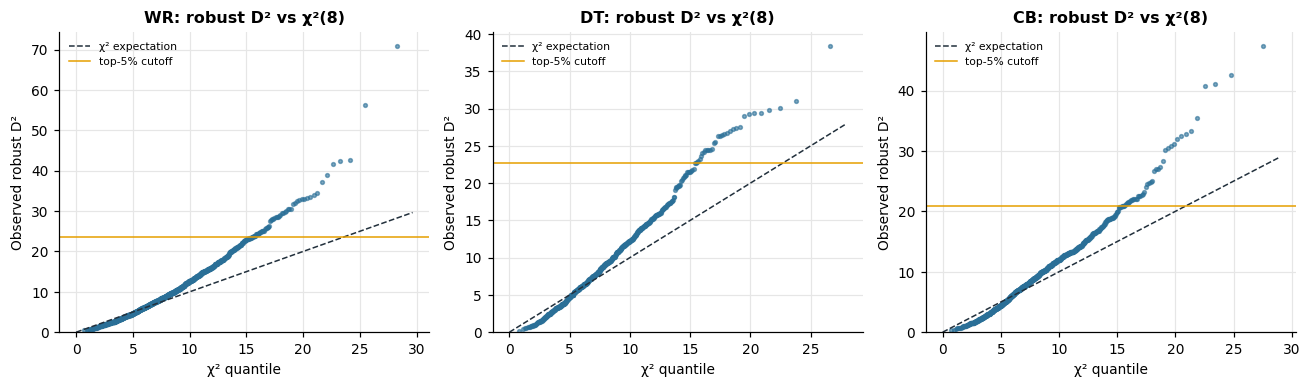

Share of prospects beyond the χ² 97.5% point (full view): 10.4%  (normal theory expects 2.5%)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, g in zip(axes, ["WR", "DT", "CB"]):
    s = df[df.grp == g]
    k = len(s.features.iloc[0].split(","))
    observed = np.sort(s.d2_full.values)
    theoretical = chi2.ppf((np.arange(1, len(observed) + 1) - .5) / len(observed), df=k)
    ax.scatter(theoretical, observed, s=6, color="#2A6F97", alpha=.6)
    lim = theoretical.max() * 1.05
    ax.plot([0, lim], [0, lim], color="#22303C", lw=1, ls="--", label="χ² expectation")
    cut = np.quantile(observed, 1 - UNICORN_SHARE)
    ax.axhline(cut, color=TYPE_COLOR["Freak"], lw=1, label="top-5% cutoff")
    ax.set(title=f"{g}: robust D² vs χ²({k})", xlabel="χ² quantile", ylabel="Observed robust D²", ylim=(0, observed.max() * 1.05))
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
share_chi = (df.chi2_p_full < .025).mean()
print(f"Share of prospects beyond the χ² 97.5% point (full view): {share_chi:.1%}  (normal theory expects 2.5%)")

### Where the unicorns are
Weight vs 40 time for three positions. Grey is the normal range; coloured points are flagged. Some flagged players
sit inside the cloud here because they are unusual on drills this 2-D picture doesn't show.

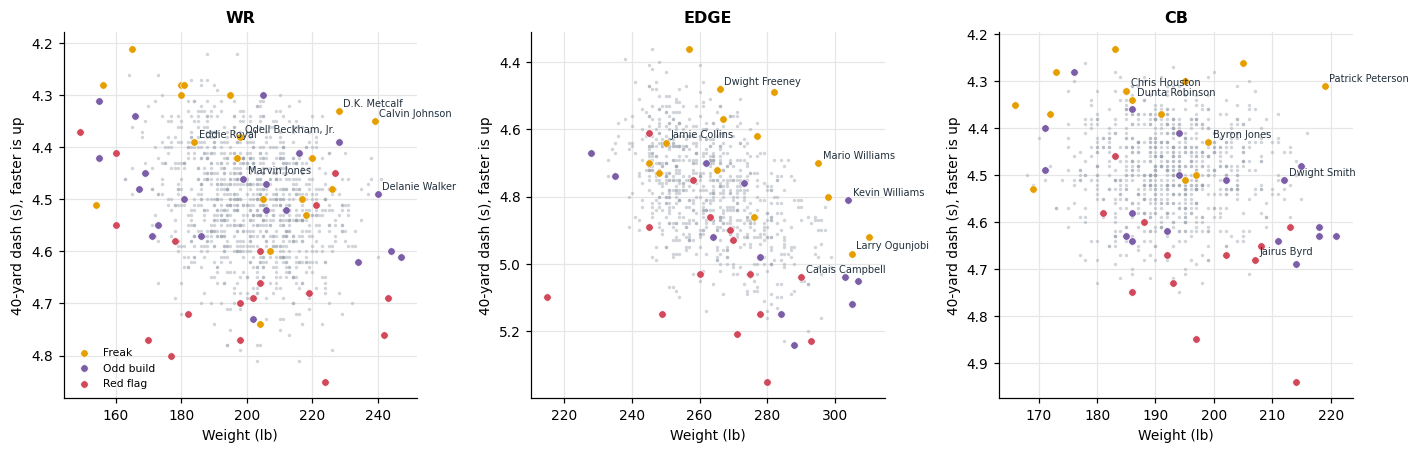

In [ ]:
def scatter_types(ax, s, x, y):
    ax.scatter(s[~s.unicorn][x], s[~s.unicorn][y], s=5, color=TYPE_COLOR["Typical"], alpha=.45, lw=0)
    for t in TYPE_ORDER[:3]:
        u = s[s.utype == t]
        ax.scatter(u[x], u[y], s=24, color=TYPE_COLOR[t], edgecolor="white", lw=.4, label=t, zorder=3)


def label_points(ax, rows, x, y, fontsize=6.5):
    for _, r in rows.iterrows():
        ax.annotate(r.player_name, (r[x], r[y]), xytext=(3, 3), textcoords="offset points", fontsize=fontsize, color="#22303C")


fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, g in zip(axes, ["WR", "EDGE", "CB"]):
    s = df[df.grp == g]
    scatter_types(ax, s, "wt", "forty")
    label_points(ax, s[s.unicorn].nlargest(6, "w_av"), "wt", "forty")
    ax.invert_yaxis()
    ax.set(title=g, xlabel="Weight (lb)", ylabel="40-yard dash (s), faster is up")
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

# We're excited to work on the future of this project over the coming weeks!